# traffic flow, trying some stuff

<div align="center">
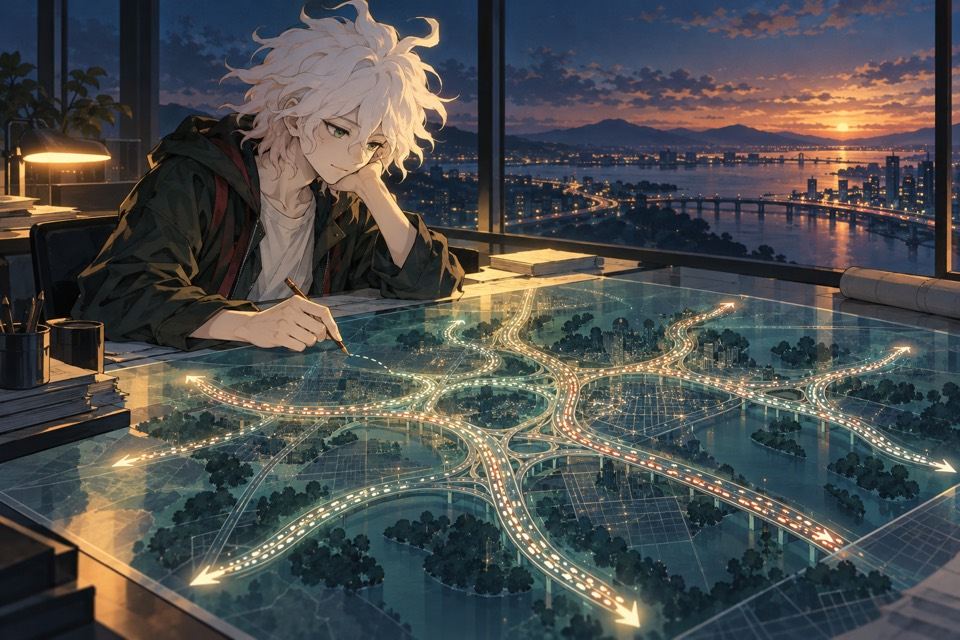
</div>

## source and credit

This version (V6) replaces our earlier reimplementation with an **inference-only reproduction of Robina Mirbahar's version 3** of [TrafficFlowBench Physics-Guided State & ODME](https://www.kaggle.com/code/robinamirbahar/trafficflowbench-physics-guided-state-odme?scriptVersionId=361713245). The code cell below is the upstream notebook **`autokagon/public-fast-gpu-inference`** (https://www.kaggle.com/code/autokagon/public-fast-gpu-inference), kept unchanged apart from one flag (`--backend numpy` instead of `gpu`, so this version runs on CPU), with its changelog and intro cells.

Credit:
- **Robina Mirbahar**, original recipe and version 3 notebook (https://www.kaggle.com/code/robinamirbahar/trafficflowbench-physics-guided-state-odme).
- **Anubisyy**, public CatBoost/LightGBM/NNLS pipeline whose output is an input (https://www.kaggle.com/code/anubisyy/catboost-lgbm-nnls-pipeline-top-50-0-86517).
- **Prabhav Semwal / Yeash**, public Trees + U-Net + CNN predecessor output, also an input (https://www.kaggle.com/code/yeashusemwal/trafficflowbench-trees-u-net-cnn-lb-0-87).
- **autokagon**, the inference-speed reproduction this cell comes from (https://www.kaggle.com/code/autokagon/public-fast-gpu-inference).

Licence: Kaggle notebooks default to Apache-2.0 unless an author states otherwise. The upstream inference notebook says its shared code stays subject to its authors' rights and the competition public-code terms. We have not verified the upstream leaderboard figures ourselves.

Inputs: the three public sources above, mirrored as kernel and dataset sources. No training runs here, no internet.

# Changelog

- v6: Load two independent panel grids concurrently; preserve all prediction arithmetic.
- v5: Build positional panel groups before GPU workers to avoid shared pandas index-engine access.
- v4: Positional state gathers; target run failed during concurrent pandas index lookup, no submission.
- v3: Project unused predecessor CSV columns and keep identifiers in Arrow; prediction recipe unchanged.
- v2: Read monthly Parquet fragments concurrently.
- v1: Credit and reproduce Robina v3 with Arrow I/O and two-GPU state arithmetic.


# public fast GPU inference

Equivalent inference for **Robina Mirbahar's version 3** of [TrafficFlowBench Physics-Guided State & ODME](https://www.kaggle.com/code/robinamirbahar/trafficflowbench-physics-guided-state-odme?scriptVersionId=361713245).

Credit to **Robina Mirbahar**, **Anubisyy** ([public models and original pipeline](https://www.kaggle.com/code/anubisyy/catboost-lgbm-nnls-pipeline-top-50-0-86517)), and **Prabhav Semwal / Yeash** ([public predecessor outputs](https://www.kaggle.com/code/yeashusemwal/trafficflowbench-trees-u-net-cnn-lb-0-87)). Their prediction recipe and constants are preserved. This notebook is an inference-speed demonstration, not an independently validated private solution.

The original is already inference-only. We load its existing public queue weights and public predecessor outputs; we neither train here nor require access to a predecessor's private training weights. All attached inputs are public. Original shared code remains subject to its authors' rights and the competition public-code terms.

Changes: gather state columns once and write the final flow column once using preserved positional indices; parse/project the root key once with Arrow, replace repeated pivots with indexed grids, write CSV with Arrow, avoid whole-grid target copies, and distribute equivalent double-precision observed-neighbor/FD arithmetic across every supplied GPU. Small tree queue predictions and the existing per-instance ODME solve remain on CPU. No LB-dependent constants were changed. CUDA compilation/warmup runs here, with its cache only in this notebook's output; no host-native binary is bundled.

Numerical equivalence is checked on all 6,980,503 rows against scored version 3 locally, then against this Kaggle output before submission. State/queue/ODME comparisons and setup, inference, output and full-run timings are saved. The two test months are fully released, so these timings cover the complete test size. The private pipeline adopts nothing from this public recipe without its own CV gain.

This version also reads the month Parquet fragments concurrently with Arrow instead of serial per-file reads. The current run records its own full-size timing breakdown. The original code timer was 196.5 seconds; our first optimized version measured 84.5 seconds on Kaggle. These are observed environments, not a GPU-only causal speedup claim.

V6 reads two independent panel/split grids concurrently, retaining the original grid order and metadata. The full target run records actual end-to-end timings; no inference arithmetic or prediction constants change.


In [ ]:
import json,sys,subprocess,platform,importlib.metadata as metadata
from pathlib import Path
WORK=Path('/kaggle/working')
CODE = {'src/__init__.py': '"""Competition source."""\n', 'src/public_runtime.py': '"""Inference speed utilities for the separately credited public recipe."""\nfrom pathlib import Path\nfrom concurrent.futures import ThreadPoolExecutor\nimport time\nimport numpy as np\nimport pandas as pd\nimport pyarrow as pa\nimport pyarrow.csv as pcsv\nimport pyarrow.dataset as pds\nTIMINGS={}\n\n\ndef install_io(data,compact_csv=False):\n    original=pd.read_csv;cache={};data=Path(data)\n    allcols=[\'submission_id\',\'task\',\'panel\',\'timestamp\',\'link_id\',\'mask_regime\',\'window_id\',\'departure_time\',\'path_id\']\n    def reader(path,*args,**kwargs):\n        path=Path(path)\n        if path==data/\'submission_key.csv\':\n            if \'key\' not in cache:\n                table=pcsv.read_csv(path,convert_options=pcsv.ConvertOptions(include_columns=allcols,column_types={c:pa.string() for c in allcols}))\n                cache[\'key\']=table.to_pandas(types_mapper=pd.ArrowDtype)\n            return cache[\'key\'][kwargs[\'usecols\']].copy()\n        if path.name in [\'submission.csv\',\'sample_submission.csv\']:\n            start=time.perf_counter()\n            table=pcsv.read_csv(path,convert_options=pcsv.ConvertOptions(include_columns=kwargs.get(\'usecols\')))\n            frame=table.to_pandas(types_mapper=(lambda t: pd.ArrowDtype(t) if pa.types.is_string(t) else None)\n                                  if compact_csv else None)\n            TIMINGS[\'csv_table_read_seconds\']=TIMINGS.get(\'csv_table_read_seconds\',0)+time.perf_counter()-start\n            return frame\n        return original(path,*args,**kwargs)\n    pd.read_csv=reader\n\n\ndef fast_write_csv(frame,path):\n    start=time.perf_counter()\n    pcsv.write_csv(pa.Table.from_pandas(frame,preserve_index=False),path)\n    TIMINGS[\'output_write_seconds\']=time.perf_counter()-start\n\n\ndef fast_matrices(frame,panel):\n    times=pd.Index(sorted(frame.timestamp.unique()));links=pd.Index(panel.links)\n    r=times.get_indexer(frame.timestamp);c=links.get_indexer(frame.link_id)\n    assert (r>=0).all() and (c>=0).all() and len(frame)==len(times)*len(links)\n    shape=(len(times),len(links));out=[]\n    for col in [\'speed_kmh\',\'flow_vph\',\'is_score_eligible\']:\n        x=np.empty(shape,dtype=np.float32);x[r,c]=frame[col].to_numpy(dtype=np.float32)\n        out.append(np.nan_to_num(x,nan=0).astype(bool) if col==\'is_score_eligible\' else x)\n    return times,*out\n\n\ndef fast_month_frame(root,panel,month,split=\'train\'):\n    base=Path(root)/\'corridors\'/panel/split/(\'mainline_states\' if split==\'train\' else \'mainline_states_masked\')\n    paths=sorted(base.glob(f\'year_month={month}/*.parquet\' if split==\'train\' else \'**/*.parquet\'))\n    assert paths\n    table=pds.dataset([str(p) for p in paths],format=\'parquet\').to_table(\n        columns=[\'timestamp\',\'link_id\',\'speed_kmh\',\'flow_vph\',\'is_score_eligible\'],\n        fragment_readahead=16,batch_readahead=2,use_threads=True)\n    frame=table.to_pandas();frame[\'link_id\']=frame.link_id.astype(str)\n    assert not frame.duplicated([\'timestamp\',\'link_id\']).any()\n    return frame\n\n\ndef state_postprocess(st_key,fd_lookup,panel_grids,backend):\n    start=time.perf_counter()\n    if backend==\'gpu\':\n        import cupy as cp\n        devices=cp.cuda.runtime.getDeviceCount()\n        # Compile/warm in this inference run, in its own output cache.\n        for device in range(devices):\n            with cp.cuda.Device(device):\n                x=cp.zeros(8,dtype=cp.float64);mask=cp.ones(8,dtype=cp.bool_)\n                y=cp.where(mask,.94*x+.03*(x+x),x)\n                cp.asnumpy(cp.clip(y/cp.maximum(x,5),0,None))\n    else:cp=None;devices=1\n    TIMINGS[\'gpu_import_context_warmup_seconds\']=time.perf_counter()-start\n    compute_start=time.perf_counter();batches=[]\n    all_v=st_key[\'v\'].to_numpy(np.float64)\n    all_q=st_key[\'q\'].to_numpy(np.float64,copy=True)\n    all_timestamps=st_key[\'timestamp\'].to_numpy()\n    all_links=st_key[\'link_id\'].to_numpy()\n    def process(job):\n        batch_start=time.perf_counter()\n        panel,group,device=job\n        if cp is not None:cp.cuda.Device(device).use()\n        xp=cp if cp is not None else np\n        result=[];positions=group\n        stamps=all_timestamps[positions];links=all_links[positions];pnl_fd=fd_lookup.loc[panel]\n        for split in [\'validation\',\'private\']:\n            obj,times,grid_v,grid_q,grid_e=panel_grids[panel,split]\n            rr=times.get_indexer(stamps);valid=rr>=0\n            if not valid.any():continue\n            index=positions[valid];r=rr[valid];c=pd.Index(obj.links).get_indexer(links[valid])\n            v=xp.asarray(all_v[index]);q=xp.asarray(all_q[index])\n            # Only true observed neighbors contribute. Filled target grids are unnecessary.\n            interior=(r%288>0)&(r%288<287)\n            prev=(r-1).clip(0,len(times)-1);nxt=(r+1).clip(0,len(times)-1)\n            observed=grid_e&np.isfinite(grid_v)&np.isfinite(grid_q)&(grid_v>1)\n            both=xp.asarray(interior&observed[prev,c]&observed[nxt,c])\n            vp=xp.asarray(grid_v[prev,c],dtype=xp.float64);vn=xp.asarray(grid_v[nxt,c],dtype=xp.float64)\n            qp=xp.asarray(grid_q[prev,c],dtype=xp.float64);qn=xp.asarray(grid_q[nxt,c],dtype=xp.float64)\n            kp=qp/xp.maximum(vp,5);kn=qn/xp.maximum(vn,5)\n            current=q/xp.maximum(v,5)\n            # Preserve original interior rounding, even when neither neighbor qualifies.\n            target=xp.where(both,.94*current+.03*(kp+kn),current)\n            update=xp.where(xp.asarray(interior),xp.clip(target*v,0,None),q)\n            def params(name):return xp.asarray(pnl_fd.reindex(obj.links)[name].to_numpy(np.float64)[c])\n            cap,kc,kj,vf=[params(n) for n in [\'capacity_vph\',\'critical_density\',\'k_jam\',\'free_speed_kmh\']]\n            w=cap/xp.maximum(kj-kc,10)\n            maximum=xp.minimum(1.06*cap,(w*kj)/(1+w/xp.maximum(v,5)))\n            update=xp.where((v<.58*vf)&(update>maximum),.96*update+.04*maximum,update)\n            update=xp.clip(update,0,None)\n            result.append((index,cp.asnumpy(update) if cp is not None else update))\n        batches.append({\'panel\':panel,\'device\':device if cp is not None else None,\'seconds\':time.perf_counter()-batch_start})\n        return result\n    # Build positional groups before GPU workers; pandas lazily builds index\n    # engines and must not be queried concurrently for this conversion.\n    jobs=[(p,g,i%devices) for i,(p,g) in enumerate(st_key.groupby(\'panel\').indices.items())]\n    if cp is None:results=map(process,jobs)\n    else:\n        executor=ThreadPoolExecutor(max_workers=devices);results=executor.map(process,jobs)\n    for result in results:\n        for indices,values in result:all_q[indices]=values\n    if cp is not None:executor.shutdown()\n    st_key[\'q\']=all_q\n    TIMINGS[\'state_postprocess_wall_seconds\']=time.perf_counter()-compute_start\n    TIMINGS[\'panel_batches\']=batches\n    return devices if cp is not None else 0\n', 'scripts/public_fast/benchmark.py': '"""Reproduce or accelerate the exact public v3 recipe; no training calls."""\nimport argparse,hashlib,json,os,sys,time\nfrom pathlib import Path\nSTART=time.perf_counter();EPOCH_START=time.time();ROOT=Path(__file__).resolve().parents[2];sys.path.insert(0,str(ROOT))\nap=argparse.ArgumentParser();ap.add_argument(\'--data\',type=Path,required=True);ap.add_argument(\'--inputs\',type=Path,required=True);ap.add_argument(\'--output\',type=Path,required=True);ap.add_argument(\'--backend\',choices=[\'original\',\'numpy\',\'gpu\'],default=\'numpy\');ap.add_argument(\'--manifest\',type=Path);ap.add_argument(\'--parallel-parquet\',action=\'store_true\');ap.add_argument(\'--compact-csv\',action=\'store_true\');ap.add_argument(\'--parallel-grids\',action=\'store_true\');a=ap.parse_args();a.output=a.output.resolve();a.output.mkdir(exist_ok=True,parents=True)\nos.environ[\'CUPY_CACHE_DIR\']=str(a.output/\'compile-cache\')\nos.environ[\'CUDA_CACHE_PATH\']=str(a.output/\'cuda-cache\')\nfrom src.public_runtime import install_io,fast_write_csv,fast_matrices,state_postprocess,fast_month_frame,TIMINGS\nsrc=(ROOT/\'vendor/public_fast/robina_v3.py\').read_text()\nsrc=src.replace(\'import matplotlib.pyplot as plt\',\'\');src=src[:src.index(\'fig, axes = plt.subplots\')]\nsrc=src.replace("WORK = Path(\'/kaggle/working\')",\'WORK = Path(\'+repr(str(a.output))+\')\').replace("TMP_MOD = Path(\'/tmp/tfb_modules\')",\'TMP_MOD = WORK / "modules"\').replace("TMP_OUT = Path(\'/tmp/tfb_outputs\')",\'TMP_OUT = WORK / "outputs"\')\nsrc=src.replace("for root, _, files in os.walk(\'/kaggle/input\'):","for root, _, files in os.walk("+repr(str(a.inputs.resolve()))+"):")\nsrc=src.replace("DATA = resolve_input_file(\'submission_key.csv\').parent",\'DATA = Path(\'+repr(str(a.data.resolve()))+\')\')\nsrc=src.replace("SRC_MOD = resolve_input_file(\'queue_ongoing.py\').parent",\'SRC_MOD = ASSETS\')\nsrc=src.replace(\'onset_lgb = lgb.Booster\',"MODEL_LOAD_START=time.perf_counter()\\nonset_lgb = lgb.Booster")\nsrc=src.replace("onset_cat.load_model(str(ASSETS / \'onset.cbm\'))","onset_cat.load_model(str(ASSETS / \'onset.cbm\'))\\nMODEL_LOAD_SECONDS=time.perf_counter()-MODEL_LOAD_START")\nsrc=src.replace(\'panel_grids = {}\',\'GRID_START=time.perf_counter()\\npanel_grids = {}\')\nsrc=src.replace(\'q_pieces = []\',\'GRID_SECONDS=time.perf_counter()-GRID_START\\nQUEUE_START=time.perf_counter()\\nq_pieces = []\')\nsrc=src.replace(\'queue_df = pd.concat(q_pieces, ignore_index=True)\',\'QUEUE_SECONDS=time.perf_counter()-QUEUE_START\\nqueue_df = pd.concat(q_pieces, ignore_index=True)\')\nif a.backend!=\'original\':\n    install_io(a.data.resolve(),compact_csv=a.compact_csv)\n    if a.compact_csv:\n        needle="pub = pd.read_csv(stage2_root / \'submission.csv\', usecols=[\'submission_id\', \'task\', \'speed_kmh\', \'flow_vph\', \'queue_pred\'])"\n        assert src.count(needle)==1\n        src=src.replace(needle,"pub = pd.read_csv(stage2_root / \'submission.csv\', usecols=[\'speed_kmh\', \'flow_vph\'])")\n    src=src.replace(\'import state_model as sm\',\'import state_model as sm\\nsm.matrices = fast_matrices\')\n    if a.parallel_parquet:\n        src=src.replace(\'sm.matrices = fast_matrices\',"sm.matrices = fast_matrices\\nsm.month_frame = lambda name, month, split=\'train\': fast_month_frame(DATA,name,month,split)")\n    if a.parallel_grids:\n        old="""panel_grids = {}\nfor split in (\'validation\', \'private\'):\n    for pi, name in enumerate(ALL_PANELS):\n        p_obj = sm.Panel(name, pi)\n        frm = sm.month_frame(name, \'\', split=split)\n        panel_grids[(name, split)] = (p_obj, *sm.matrices(frm, p_obj))"""\n        new="""from concurrent.futures import ThreadPoolExecutor\n# Build independent Panel metadata before workers; preserve original key order.\ngrid_jobs = [(name, split, sm.Panel(name, pi))\n             for split in (\'validation\', \'private\') for pi, name in enumerate(ALL_PANELS)]\ndef load_public_grid(job):\n    name, split, obj = job\n    frame = sm.month_frame(name, \'\', split=split)\n    return (name, split), (obj, *sm.matrices(frame, obj))\nwith ThreadPoolExecutor(max_workers=2) as grid_pool:\n    panel_grids = dict(grid_pool.map(load_public_grid, grid_jobs))"""\n        assert src.count(old)==1\n        src=src.replace(old,new)\n    start=src.index(\'for pnl, grp_idx in st_key.groupby(\\\'panel\\\').groups.items():\')\n    stop=src.index("sub.loc[st_mask, \'speed_kmh\']",start)\n    src=src[:start]+f"gpu_count = state_postprocess(st_key, fd_lookup, panel_grids, {a.backend!r})\\n"+src[stop:]\n    src=src.replace(\'sub.to_csv(out_file, index=False)\',\'fast_write_csv(sub,out_file)\')\nnamespace=globals()|{\'display\':lambda *args,**kwargs:None}\nsetup=time.perf_counter()-START\nexec(compile(src,\'<credited Robina v3 inference recipe>\',\'exec\'),namespace)\nreport={\'backend\':a.backend,\'support_import_seconds\':setup,\'imports_seconds\':namespace[\'T0\']-EPOCH_START,\n    \'model_load_seconds\':namespace[\'MODEL_LOAD_SECONDS\'],\'grid_load_seconds\':namespace[\'GRID_SECONDS\'],\n    \'queue_features_and_inference_seconds\':namespace[\'QUEUE_SECONDS\'],\'wall_seconds\':time.perf_counter()-START,\n    \'recipe_timer_seconds\':time.time()-namespace[\'T0\'],\'gpus_used\':namespace.get(\'gpu_count\',0),**TIMINGS}\n(a.output/\'timings.json\').write_text(json.dumps(report,indent=2)+\'\\n\');print(json.dumps(report),flush=True)\nif a.manifest:\n    manifest=json.loads(a.manifest.read_text())\n    roots={\'assets\':namespace[\'ASSETS\'],\'anubis\':namespace[\'stage2_root\'],\'yeash\':namespace[\'stage1_root\'],\'competition\':a.data.resolve()}\n    for entry in manifest[\'public_input_files\']:\n        path=roots[entry[\'role\']]/entry[\'relative\']\n        assert hashlib.sha256(path.read_bytes()).hexdigest()==entry[\'sha256\'],(entry[\'role\'],entry[\'relative\'])\n    prediction=a.output/\'submission.csv\'\n    (a.output/\'inference-report.json\').write_text(json.dumps({\'rows\':len(namespace[\'sub\']),\'elapsed_seconds\':report[\'wall_seconds\'],\n        \'assets\':manifest,\'submission_sha256\':hashlib.sha256(prediction.read_bytes()).hexdigest(),\'timings\':report},indent=2)+\'\\n\')\n', 'vendor/public_fast/robina_v3.py': "from pathlib import Path\nimport os, sys, json, gc, time, shutil, warnings\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom scipy import sparse\nfrom scipy.linalg import solve\nfrom scipy.optimize import minimize\nfrom threadpoolctl import threadpool_limits\nimport lightgbm as lgb\nfrom catboost import CatBoostClassifier\n\nwarnings.filterwarnings('ignore')\nTHREADS = min(4, os.cpu_count() or 1)\nos.environ.update(OMP_NUM_THREADS=str(THREADS), OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')\nT0 = time.time()\n\ndef resolve_input_file(filename):\n    for root, _, files in os.walk('/kaggle/input'):\n        if filename in files:\n            return Path(root) / filename\n    raise FileNotFoundError(f'Required input {filename} not found')\n\nDATA = resolve_input_file('submission_key.csv').parent\nASSETS = resolve_input_file('ongoing_lgb.txt').parent\nSRC_MOD = resolve_input_file('queue_ongoing.py').parent\nWORK = Path('/kaggle/working')\nTMP_MOD = Path('/tmp/tfb_modules')\nTMP_OUT = Path('/tmp/tfb_outputs')\nTMP_MOD.mkdir(parents=True, exist_ok=True)\nTMP_OUT.mkdir(parents=True, exist_ok=True)\n\nfor mod_name in ('config.py', 'base_panel.py', 'state_model.py', 'queue_ongoing.py', 'queue_features.py'):\n    src_file = SRC_MOD / mod_name\n    if src_file.exists():\n        shutil.copy2(src_file, TMP_MOD / mod_name)\n\nos.environ.update(TFB_DATA_ROOT=str(DATA), TFB_OUTPUT_ROOT=str(TMP_OUT), TFB_THREADS=str(THREADS))\nsys.path.insert(0, str(TMP_MOD))\n\nprint(f'Competition Data Root : {DATA}')\nprint(f'Model Checkpoints     : {ASSETS}')\nprint(f'Active CPU Threads    : {THREADS}')\n\ncorridors_cfg = json.loads((DATA / 'config' / 'corridors.json').read_text())\nALL_PANELS = [entry['corridor_id'] for entry in corridors_cfg['panels']]\nfd_records = []\nfor pnl in ALL_PANELS:\n    fd_df = pd.read_csv(DATA / 'corridors' / pnl / 'network' / 'fd_parameters.csv', dtype={'link_id': str}).drop_duplicates('link_id')\n    fd_df['panel'] = pnl\n    fd_records.append(fd_df)\nfd_all = pd.concat(fd_records, ignore_index=True)\nprint(f'Loaded FD parameters for {len(fd_all):,} mainline links across {len(ALL_PANELS)} directional panels.')\ndisplay(fd_all.groupby('panel')[['lanes', 'free_speed_kmh', 'capacity_vph', 'critical_density', 'k_jam']].agg(['count', 'mean']).round(2))\n\nLAMBDA = 0.05\ninitial_odme = pd.read_parquet(ASSETS / 'odme_initial.parquet')\nref_t4 = {}\ntry:\n    t4_val_f = resolve_input_file('task4_validation.csv')\n    t4_prv_f = resolve_input_file('task4_private.csv')\n    t4_ref_df = pd.concat([\n        pd.read_csv(t4_val_f, dtype={'panel': str, 'departure_time': str, 'path_id': str}),\n        pd.read_csv(t4_prv_f, dtype={'panel': str, 'departure_time': str, 'path_id': str})\n    ], ignore_index=True)\n    for (pnl_k, dep_k), grp in t4_ref_df.groupby(['panel', 'departure_time']):\n        ref_t4[(str(pnl_k), str(dep_k))] = grp.set_index('path_id')['path_flow']\nexcept FileNotFoundError:\n    pass\n\ndef solve_odme_panel(name, split):\n    network = DATA / 'corridors' / name / 'network'\n    folder = DATA / 'task4' / name / split\n    paths = pd.read_csv(network / 'path_set.csv', dtype=str)\n    incidence = pd.read_csv(network / 'path_link_incidence.csv', dtype=str).drop_duplicates(['link_id', 'path_id'])\n    prior = pd.read_csv(folder / 'synthetic_weak_prior.csv', dtype={'path_id': str, 'departure_time': str})\n    counts = pd.read_csv(folder / 'synthetic_link_counts.csv', dtype={'link_id': str})\n    ids = paths.path_id.tolist()\n    path_index = {p: i for i, p in enumerate(ids)}\n    supported = set(incidence.link_id)\n    links = [link for link in counts.link_id if link in supported]\n    link_index = {link: i for i, link in enumerate(links)}\n    measured = incidence[incidence.link_id.isin(link_index)]\n    A = sparse.csr_matrix(\n        (np.ones(len(measured), dtype=np.float64), (measured.link_id.map(link_index), measured.path_id.map(path_index))),\n        shape=(len(links), len(ids))\n    )\n    c = counts.set_index('link_id').reindex(links)['count'].to_numpy(float)\n    b = prior.set_index('path_id').reindex(ids).path_flow.to_numpy(float)\n\n    def objective(f):\n        res, reg = A @ f - c, f - b\n        return float(0.5 * (res @ res + LAMBDA * (reg @ reg))), np.asarray(A.T @ res + LAMBDA * reg)\n\n    def proj_grad(f):\n        g = objective(f)[1]\n        return float(np.max(np.abs(np.where(f > 1e-7, g, np.minimum(g, 0.0)))))\n\n    departure = str(prior.departure_time.iloc[0])\n    candidates = []\n    matched = initial_odme[(initial_odme.panel == name) & (initial_odme.departure_time == departure)]\n    if len(matched) > 0:\n        f_a = np.maximum(matched.set_index('path_id').reindex(ids).path_flow.to_numpy(float), 0.0)\n        if np.isfinite(f_a).all():\n            candidates.append(f_a)\n    if (name, departure) in ref_t4:\n        f_y = np.maximum(ref_t4[(name, departure)].reindex(ids).to_numpy(float), 0.0)\n        if np.isfinite(f_y).all():\n            candidates.append(f_y)\n    if not candidates:\n        gram = (A @ A.T).toarray()\n        u = b + A.T @ solve(gram + LAMBDA * np.eye(len(c)), c - A @ b, assume_a='pos')\n        candidates.append(np.maximum(u, 0.0))\n\n    f0 = min(candidates, key=lambda x: objective(x)[0])\n    obj0, pg0 = objective(f0)[0], proj_grad(f0)\n    if pg0 > 1e-8:\n        fit = minimize(\n            objective, f0, jac=True, method='L-BFGS-B',\n            bounds=[(0.0, None)] * len(ids),\n            options={'maxiter': 10000, 'ftol': 0.0, 'gtol': 1e-10, 'maxcor': 40}\n        )\n        f_cand = np.maximum(fit.x, 0.0)\n        f = f_cand if objective(f_cand)[0] <= obj0 else f0\n        nit = int(fit.nit)\n    else:\n        f, nit = f0, 0\n\n    obj1, pg1 = objective(f)[0], proj_grad(f)\n    count_fit = 1.0 - float(np.linalg.norm(A @ f - c) / max(np.linalg.norm(c), 1e-9))\n\n    tpl = pd.read_csv(folder / 'sample_submission_path_flow.csv', dtype={'path_id': str})\n    tpl['path_flow'] = tpl.path_id.map(dict(zip(ids, f)))\n    diag = {\n        'panel': name, 'split': split, 'iterations': nit,\n        'obj_before': obj0, 'obj_after': obj1,\n        'pg_before': pg0, 'pg_after': pg1, 'count_fit': count_fit\n    }\n    return tpl, diag\n\nod_parts, od_diags = [], []\nwith threadpool_limits(limits=1, user_api='blas'):\n    for split in ('validation', 'private'):\n        for pnl in ALL_PANELS:\n            tpl_df, d = solve_odme_panel(pnl, split)\n            od_parts.append(tpl_df)\n            od_diags.append(d)\n\nodme_df = pd.concat(od_parts, ignore_index=True)\nodme_diag_df = pd.DataFrame(od_diags)\nprint(f'Task 4 ODME solved across all 20 panels in {time.time() - T0:.1f}s (max post-solve projected gradient: {odme_diag_df.pg_after.max():.2e})')\ndisplay(odme_diag_df)\n\nfrom queue_features import Panel as OnsetPanel, panel_names, HISTORY, HORIZON\nfrom queue_ongoing import Panel as OngoingPanel\nimport state_model as sm\n\nonset_lgb = lgb.Booster(model_file=str(ASSETS / 'onset_lgb.txt'))\nongoing_lgb = lgb.Booster(model_file=str(ASSETS / 'ongoing_lgb.txt'))\nonset_cat = CatBoostClassifier()\nonset_cat.load_model(str(ASSETS / 'onset.cbm'))\n\nt2_val_f = resolve_input_file('task2_validation.csv')\nt2_prv_f = resolve_input_file('task2_private.csv')\nstage1_t2 = pd.concat([\n    pd.read_csv(t2_val_f, dtype={'window_id': str, 'timestamp': str, 'link_id': str}),\n    pd.read_csv(t2_prv_f, dtype={'window_id': str, 'timestamp': str, 'link_id': str})\n], ignore_index=True)\nstage1_t2_map = stage1_t2.set_index(['window_id', 'timestamp', 'link_id'])['queue_pred']\n\nstage1_root = t2_val_f.parent.parent\nstage2_root = resolve_input_file('odme_diagnostics.csv').parent.parent\nsub = pd.read_csv(stage1_root / 'submission.csv')\npub = pd.read_csv(stage2_root / 'submission.csv', usecols=['submission_id', 'task', 'speed_kmh', 'flow_vph', 'queue_pred'])\n\nsub_key_q = pd.read_csv(DATA / 'submission_key.csv', usecols=['submission_id', 'task', 'window_id', 'timestamp', 'link_id'], dtype=str)\nsub_key_q = sub_key_q[sub_key_q['task'] == 'queue'].copy()\nsub_key_q['queue_pred_init'] = sub.loc[sub['task'] == 'queue', 'queue_pred'].to_numpy(int)\ninit_q_map = sub_key_q.set_index(['window_id', 'timestamp', 'link_id'])['queue_pred_init']\n\npanel_grids = {}\nfor split in ('validation', 'private'):\n    for pi, name in enumerate(ALL_PANELS):\n        p_obj = sm.Panel(name, pi)\n        frm = sm.month_frame(name, '', split=split)\n        panel_grids[(name, split)] = (p_obj, *sm.matrices(frm, p_obj))\n\nq_pieces = []\nong_promoted, ong_cleared = 0, 0\nfor split in ('validation', 'private'):\n    for panel_no, name in enumerate(panel_names()):\n        onset_panel = OnsetPanel(name, panel_no)\n        ongoing_panel = OngoingPanel(name, panel_no)\n        _, grid_times, grid_v, grid_q, grid_e = panel_grids[(name, split)]\n        folder = DATA / 'task2' / name / split\n        windows = pd.read_csv(folder / 'window_index.csv')\n        history = pd.read_parquet(folder / 'window_history.parquet')\n        adj = ongoing_panel.incoming + ongoing_panel.outgoing\n\n        for w in windows.itertuples(index=False):\n            origin = pd.Timestamp(w.forecast_origin)\n            times = pd.date_range(end=origin - pd.Timedelta(minutes=5), periods=HISTORY, freq='5min', tz='UTC').strftime('%Y-%m-%dT%H:%M:%SZ')\n            h = history[history.window_id == w.window_id].copy()\n            h['link_id'] = h.link_id.astype(str)\n            assert pd.to_datetime(h.timestamp, utc=True).max() < origin\n            mat = lambda col: h.pivot(index='timestamp', columns='link_id', values=col).reindex(index=times, columns=onset_panel.links).to_numpy(dtype=np.float32)\n            speed, flow, eligible = mat('speed_kmh'), mat('flow_vph'), mat('is_score_eligible')\n\n            stamps = [(origin + pd.Timedelta(minutes=5 * step)).strftime('%Y-%m-%dT%H:%M:%SZ') for step in range(1, HORIZON + 1)]\n            idx_tuples = pd.MultiIndex.from_arrays([\n                np.repeat(w.window_id, HORIZON * len(onset_panel.links)),\n                np.repeat(stamps, len(onset_panel.links)),\n                np.tile(onset_panel.links, HORIZON)\n            ])\n            y_stage1 = stage1_t2_map.reindex(idx_tuples).to_numpy(int).reshape(HORIZON, len(onset_panel.links))\n            y_init = init_q_map.reindex(idx_tuples).to_numpy(int).reshape(HORIZON, len(onset_panel.links))\n\n            if w.condition == 'queue_onset':\n                X_on = onset_panel.features(speed, flow, eligible, origin, w.condition)[-len(onset_panel.links):]\n                p_trees = 0.5 * onset_lgb.predict(X_on, num_threads=THREADS) + 0.5 * onset_cat.predict_proba(X_on, thread_count=THREADS)[:, 1]\n                sel = p_trees >= 0.55\n                if not sel.any():\n                    sel[np.argmax(p_trees)] = True\n                pred = np.zeros((HORIZON, len(onset_panel.links)), dtype=np.uint8)\n                pred[-1] = sel.astype(np.uint8)\n            else:\n                obs = np.nan_to_num(eligible, nan=0).astype(bool)\n                X_std = ongoing_panel.features(speed, flow, obs, origin, w.condition)\n                p_std = ongoing_lgb.predict(X_std, num_threads=THREADS).reshape(HORIZON, len(ongoing_panel.links))\n\n                t_pos = grid_times.get_indexer([str(w.forecast_origin)])[0]\n                if t_pos >= 0:\n                    v_T_raw = grid_v[t_pos].copy()\n                    q_T_raw = grid_q[t_pos].copy()\n                    obs_T = np.isfinite(v_T_raw)\n                    dv = np.where(obs_T, v_T_raw - speed[-1], np.nan)\n                    neigh_dv = np.nan_to_num(ongoing_panel.neighboring(adj, dv), nan=0.0)\n                    v_T = np.where(obs_T, v_T_raw, np.clip(speed[-1] + np.clip(neigh_dv, -15.0, 15.0), 5.0, 130.0))\n                    q_T = np.where(np.isfinite(q_T_raw), q_T_raw, flow[-1])\n                    speed_sh = np.vstack([speed[1:], v_T[None, :]])\n                    flow_sh = np.vstack([flow[1:], q_T[None, :]])\n                    obs_sh = np.vstack([obs[1:], np.ones((1, len(ongoing_panel.links)), dtype=bool)])\n                    X_sh = ongoing_panel.features(speed_sh, flow_sh, obs_sh, origin + pd.Timedelta(minutes=5), w.condition)\n                    p_sh_raw = ongoing_lgb.predict(X_sh, num_threads=THREADS).reshape(HORIZON, len(ongoing_panel.links))\n                    p_T = np.vstack([p_sh_raw[0:1], p_sh_raw[0:5]])\n                    p_causal = 0.60 * p_std + 0.40 * p_T\n                    q_now = (v_T <= ongoing_panel.cut)[None, :]\n                    free_now = (v_T > ongoing_panel.cut + 12.0)[None, :]\n                else:\n                    p_causal = p_std\n                    p_T = p_std\n                    q_now = np.zeros((1, len(ongoing_panel.links)), dtype=bool)\n                    free_now = np.zeros((1, len(ongoing_panel.links)), dtype=bool)\n\n                pred = y_init.copy().astype(np.uint8)\n                promote_mask = (pred == 0) & (y_stage1 == 1) & (p_std >= 0.39) & (p_causal >= 0.48) & q_now\n                clear_mask = (pred == 1) & (p_std < 0.48) & (p_T < 0.22) & (p_causal < 0.38) & free_now\n                pred[promote_mask] = 1\n                pred[clear_mask] = 0\n                ong_promoted += int(promote_mask.sum())\n                ong_cleared += int(clear_mask.sum())\n\n            q_pieces.append(pd.DataFrame({\n                'window_id': idx_tuples.get_level_values(0),\n                'timestamp': idx_tuples.get_level_values(1),\n                'link_id': idx_tuples.get_level_values(2),\n                'queue_pred': pred.ravel()\n            }))\n\nqueue_df = pd.concat(q_pieces, ignore_index=True)\nq_indexed = queue_df.set_index(['window_id', 'timestamp', 'link_id'])['queue_pred']\nq_matched = q_indexed.reindex(pd.MultiIndex.from_frame(sub_key_q[['window_id', 'timestamp', 'link_id']])).to_numpy(int)\nsub.loc[sub['task'] == 'queue', 'queue_pred'] = q_matched\nprint(f'Task 2 complete in {time.time() - T0:.1f}s | Ongoing causal-T promotions: {ong_promoted}, clearances: {ong_cleared}')\n\nst_mask = sub['task'] == 'state'\n# 0.52 * (2*sub - pub) + 0.48 * pub = 1.04 * sub - 0.04 * pub\nv_blend = np.clip(1.04 * sub.loc[st_mask, 'speed_kmh'].to_numpy(float) - 0.04 * pub.loc[st_mask, 'speed_kmh'].to_numpy(float), 5.0, 132.0)\nq_blend = np.clip(1.04 * sub.loc[st_mask, 'flow_vph'].to_numpy(float) - 0.04 * pub.loc[st_mask, 'flow_vph'].to_numpy(float), 0.0, None)\n\nst_key = pd.read_csv(DATA / 'submission_key.csv', usecols=['submission_id', 'task', 'panel', 'timestamp', 'link_id', 'mask_regime'], dtype=str)\nst_key = st_key[st_key['task'] == 'state'].copy()\nst_key['v'] = v_blend\nst_key['q'] = q_blend\n\nfd_lookup = fd_all.set_index(['panel', 'link_id'])\n\nfor pnl, grp_idx in st_key.groupby('panel').groups.items():\n    sub_rows = st_key.loc[grp_idx]\n    pnl_fd = fd_lookup.loc[pnl]\n    for split in ('validation', 'private'):\n        p_obj, grid_times, grid_v, grid_q, grid_e = panel_grids[(pnl, split)]\n        t_indexer = grid_times.get_indexer(sub_rows['timestamp'])\n        valid_split = t_indexer >= 0\n        if not valid_split.any():\n            continue\n        loc_idx = grp_idx[valid_split]\n        r_idx = t_indexer[valid_split]\n        c_idx = pd.Index(p_obj.links).get_indexer(st_key.loc[loc_idx, 'link_id'])\n\n        v_pred = st_key.loc[loc_idx, 'v'].to_numpy(np.float64)\n        q_pred = st_key.loc[loc_idx, 'q'].to_numpy(np.float64)\n\n        v_full = grid_v.copy().astype(np.float64)\n        q_full = grid_q.copy().astype(np.float64)\n        obs_mask = grid_e & np.isfinite(v_full) & np.isfinite(q_full) & (v_full > 1.0)\n        v_full[r_idx, c_idx] = v_pred\n        q_full[r_idx, c_idx] = q_pred\n        k_full = np.where(v_full > 1.0, q_full / np.maximum(v_full, 5.0), np.nan)\n\n        slot_in_day = r_idx % 288\n        interior = (slot_in_day > 0) & (slot_in_day < 287)\n        r_int, c_int = r_idx[interior], c_idx[interior]\n\n        # Only anchor flow when BOTH t-1 and t+1 are true score-eligible observed detector readings\n        both_obs = obs_mask[r_int - 1, c_int] & obs_mask[r_int + 1, c_int]\n        k_prev = np.where(both_obs, k_full[r_int - 1, c_int], 0.0)\n        k_next = np.where(both_obs, k_full[r_int + 1, c_int], 0.0)\n        k_curr = q_pred[interior] / np.maximum(v_pred[interior], 5.0)\n        k_target = np.where(both_obs, 0.94 * k_curr + 0.03 * (k_prev + k_next), k_curr)\n\n        q_upd = q_pred.copy()\n        q_upd[interior] = np.clip(k_target * v_pred[interior], 0.0, None)\n\n        # Calibrated Triangular FD Upper-Envelope Guardrail using exact critical_density and k_jam\n        cap_arr = pnl_fd.reindex(p_obj.links)['capacity_vph'].to_numpy(np.float64)[c_idx]\n        kc_arr = pnl_fd.reindex(p_obj.links)['critical_density'].to_numpy(np.float64)[c_idx]\n        kj_arr = pnl_fd.reindex(p_obj.links)['k_jam'].to_numpy(np.float64)[c_idx]\n        vf_arr = pnl_fd.reindex(p_obj.links)['free_speed_kmh'].to_numpy(np.float64)[c_idx]\n        w_arr = cap_arr / np.maximum(kj_arr - kc_arr, 10.0)\n        q_fd_max = np.minimum(1.06 * cap_arr, (w_arr * kj_arr) / (1.0 + w_arr / np.maximum(v_pred, 5.0)))\n        congested_excess = (v_pred < 0.58 * vf_arr) & (q_upd > q_fd_max)\n        q_upd = np.where(congested_excess, 0.96 * q_upd + 0.04 * q_fd_max, q_upd)\n\n        st_key.loc[loc_idx, 'q'] = np.clip(q_upd, 0.0, None)\n\nsub.loc[st_mask, 'speed_kmh'] = st_key['v'].to_numpy(float)\nsub.loc[st_mask, 'flow_vph'] = st_key['q'].to_numpy(float)\n\n# Map Exact-KKT ODME path_flow into submission order\nod_key = pd.read_csv(DATA / 'submission_key.csv', usecols=['submission_id', 'task', 'panel', 'departure_time', 'path_id'], dtype=str)\nod_key = od_key[od_key['task'] == 'odme']\nod_indexed = odme_df.astype({'panel': str, 'departure_time': str, 'path_id': str}).set_index(['panel', 'departure_time', 'path_id'])['path_flow']\nod_matched = od_indexed.reindex(pd.MultiIndex.from_frame(od_key[['panel', 'departure_time', 'path_id']])).to_numpy(float)\nassert np.isfinite(od_matched).all(), 'Missing ODME rows after reindex'\nsub.loc[sub['task'] == 'odme', 'path_flow'] = np.clip(od_matched, 0.0, None)\nsub['queue_pred'] = sub['queue_pred'].astype(int)\n\ntpl = pd.read_csv(DATA / 'sample_submission.csv', usecols=['submission_id', 'task'])\nchecks = {\n    'row count': len(sub) == len(tpl),\n    'template order': bool((sub.submission_id.values == tpl.submission_id.values).all()),\n    'no missing': not sub.isna().any().any(),\n    'all finite': bool(np.isfinite(sub[['speed_kmh', 'flow_vph', 'path_flow']].to_numpy()).all()),\n    'binary queues': set(sub.queue_pred.unique()) <= {0, 1},\n    'empty-road guard': float((sub.loc[st_mask, 'flow_vph'] < 50).mean()) <= 0.2\n}\nassert all(checks.values()), f'Validation checks failed: {checks}'\n\nout_file = WORK / 'submission.csv'\nsub.to_csv(out_file, index=False)\nprint(f'Saved verified submission.csv ({len(sub):,} rows, {out_file.stat().st_size:,} bytes) in {time.time() - T0:.1f}s')\ndisplay(pd.Series(checks).to_frame('passed'))\n\nfig, axes = plt.subplots(1, 3, figsize=(16, 4.5))\nst_sample = sub[sub['task'] == 'state'].sample(n=50000, random_state=42)\naxes[0].scatter(st_sample['speed_kmh'], st_sample['flow_vph'], s=2, alpha=0.18, color='#0072B2')\naxes[0].set_title('Task 1 & 3: Reconstructed Flow vs. Speed (LWR + FD Guided)')\naxes[0].set_xlabel('Speed (km/h)')\naxes[0].set_ylabel('Flow (vph)')\n\naxes[1].bar(odme_diag_df['panel'].iloc[:10], odme_diag_df['count_fit'].iloc[:10], color='#009E73', edgecolor='black')\naxes[1].set_ylim(0.999, 1.00005)\naxes[1].set_title('Task 4: Exact-KKT ODME Link Count Fit (Validation)')\naxes[1].tick_params(axis='x', rotation=45)\n\nq_rates = sub[sub['task'] == 'queue']['queue_pred'].value_counts(normalize=True).sort_index()\naxes[2].bar(['Free-Flow (0)', 'Queued (1)'], q_rates.to_numpy(), color=['#999999', '#D55E00'], edgecolor='black')\naxes[2].set_title(f'Task 2: Causal-T Queue Positive Rate ({q_rates.get(1, 0.0)*100:.2f}%)')\nplt.tight_layout()\nplt.savefig(WORK / 'tfb_physics_diagnostics.png', dpi=140)\nplt.show()"}
MANIFEST = {'release_name': 'tfb-public-fast-v6', 'cv': None, 'cv_std': None, 'cv_strategy_commit': '6405fc0', 'original_author': 'Robina Mirbahar', 'original_kernel': 'robinamirbahar/trafficflowbench-physics-guided-state-odme', 'original_version': 3, 'original_session': 361713245, 'original_public_lb': 0.87212, 'public_sources': {'anubis_session': 355402039, 'yeash_session': 358577897, 'public_assets_dataset_version_id': 20337563}, 'public_input_files': [{'role': 'anubis', 'relative': 'predictions/odme_diagnostics.csv', 'sha256': '34cd93a650f072fd4a753290b197d5ff9988d04e59dd464fc4150fbc4d5e0878'}, {'role': 'anubis', 'relative': 'submission.csv', 'sha256': 'f89f3b1118f945f6afb854c42bd689f04e870638b484b0d17aae58ce8295e0b4'}, {'role': 'yeash', 'relative': 'submission.csv', 'sha256': '457be3991e1e6a063324c38f6fccdf4477aceb779fe1e30767d860b8508fe834'}, {'role': 'yeash', 'relative': 'task2/task2_private.csv', 'sha256': 'c47121b7f2eeb16bd7e4ce96c1c0275d98ba117c0e32220245d57e7428314abc'}, {'role': 'yeash', 'relative': 'task2/task2_validation.csv', 'sha256': '8681e5dba947d78233f91d11d4cfd7a3dd15c7d67a94af37431943f07b516876'}, {'role': 'yeash', 'relative': 'task4/task4_private.csv', 'sha256': 'b9fc7ad21826926163578ef0477453ce2ec65e4fc3874e49061a36836dc95d1f'}, {'role': 'yeash', 'relative': 'task4/task4_validation.csv', 'sha256': '75f0ebb1c4adc73e352d60f7525e99f5f1847ac6ea91b7a9444417dc8ea2ae58'}, {'role': 'assets', 'relative': 'config.py', 'sha256': '148ff20367ce1300b16db7fa5e908f249cefcc61ec264114ce7418efa4fbc0ef'}, {'role': 'assets', 'relative': 'base_panel.py', 'sha256': '987d21f29740cb832a24dcdd8f0b8c559054bb7f865b21a7820f0f2cb1c7d530'}, {'role': 'assets', 'relative': 'state_model.py', 'sha256': '00f0f8f90ad0da85ceac1e22a20980f13c4f4c66309e4e90c50c8cd255cdbfc7'}, {'role': 'assets', 'relative': 'queue_ongoing.py', 'sha256': '1a0cc30ac91f16689d780edec2f1b76cf8ba3a7aaf79e96761b28efc316b6f83'}, {'role': 'assets', 'relative': 'queue_features.py', 'sha256': '2fb8a8e1b7fbdab3ca4c6428c1394f8501ff7c4aa5ed927ea1eb133a568a04fe'}, {'role': 'assets', 'relative': 'ongoing_lgb.txt', 'sha256': 'cf0c06aba8502d08e96a256f8727731d847cf893a9a2651027c9d79a7ce7ec18'}, {'role': 'assets', 'relative': 'onset_lgb.txt', 'sha256': '8649f5b579b78332e83f6cd92a81a7f8fb6626a119205293ec5edcc18f344fe2'}, {'role': 'assets', 'relative': 'onset.cbm', 'sha256': '06079b78972665f6f68c490f11733a50e708529c7d503daac9279493fd12da13'}, {'role': 'assets', 'relative': 'odme_initial.parquet', 'sha256': '1566559614b9da1f08688a9b93af8ac42f288c884d4d932f33e675fc684bc0ec'}, {'role': 'competition', 'relative': 'submission_key.csv', 'sha256': '8232c9ce6682fdd3120e6729a30e4514866ab492ef7b167ad3952e00478bd071'}, {'role': 'competition', 'relative': 'config/competition_contract.json', 'sha256': 'b2e40965cfd426d503dc579825dcfc37541fafc34594ff5d98f99e53ba5c4d0c'}, {'role': 'competition', 'relative': 'config/corridors.json', 'sha256': '613981c083b07e846ba10a15f5b3b3b665aab3192064a1baee330813154a3797'}], 'parallel_parquet': True, 'compact_csv': True, 'parallel_grids': True, 'training': 'none; inference-only original recipe with equivalent arithmetic and I/O optimizations'}
for relative,content in CODE.items():
    p=WORK/'solution'/relative;p.parent.mkdir(parents=True,exist_ok=True);p.write_text(content)
manifest=WORK/'frozen-public-manifest.json';manifest.write_text(json.dumps(MANIFEST,indent=2))
expected={'numpy':'2.1.3','pandas':'2.3.3','pyarrow':'23.0.1','scipy':'1.16.3','lightgbm':'4.6.0','catboost':'1.2.10','cupy-cuda12x':'14.0.1','threadpoolctl':'3.6.0'}
actual={p:metadata.version(p) for p in expected}
print(json.dumps({'architecture':platform.machine(),'python':sys.version,'packages':actual}),flush=True)
assert platform.machine()=='x86_64' and sys.version_info[:3]==(3,13,15),(platform.machine(),sys.version)
assert actual==expected,(actual,expected)
root=Path('/kaggle/input');keys=list(root.rglob('submission_key.csv'));assert len(keys)==1
subprocess.run([sys.executable,str(WORK/'solution/scripts/public_fast/benchmark.py'),'--data',str(keys[0].parent),'--inputs',str(root),'--output',str(WORK),'--backend','numpy','--parallel-parquet','--compact-csv','--parallel-grids','--manifest',str(manifest)],check=True)


## measured finding: what the inputs and the upstream change do

Measured by us on the full files (6,980,503 rows each, same keys and row order). These come from comparing saved outputs, not from a competition score.

| Pair | state speed MAD (km/h) | state flow MAD (vph) | queue_pred rows that differ |
|---|---:|---:|---:|
| anubis baseline to this output | 0.280 | 27.7 | 1,022 of 174,000 |
| anubis baseline to the previous public robin output | 0.563 | 46.2 | 1,505 of 174,000 |

This output stays much closer to the anubis baseline than the previous public robin version does. Its mean state flow is 1.5 vph below the baseline, while the previous robin version is 3.9 vph above. Whether the difference helps on the leaderboard is still open; this is the evidence we have, not a score.